# Fotografía aérea y visión estereoscópica

La fotografía aérea fue durante casi un siglo la principal fuente de información para la cartografía geológica, y sigue siendo insustituible en muchos trabajos: su resolución, del orden de decímetros, y sobre todo la posibilidad de verla en relieve con un estereoscopio permiten reconocer formas del terreno, estructuras y procesos que en una imagen de satélite plana pasan desapercibidos. En Colombia, el Instituto Geográfico Agustín Codazzi (IGAC) conserva vuelos desde la década de 1940, un archivo muy valioso para estudiar la evolución de cauces, laderas y movimientos en masa {cite}`ray1960,pacheco2006`.

## Ventajas y tipos de fotografía aérea

Entre las ventajas de la fotografía aérea están la visión de conjunto, que integra en una sola escena rasgos que en campo se ven por separado; la visión estereoscópica, que permite percibir y medir el relieve; la estabilidad geométrica de las cámaras métricas, que hace posible la fotogrametría; y el registro permanente de un momento, útil para comparar con vuelos posteriores.

Según la inclinación del eje de la cámara se distinguen tres tipos. La fotografía vertical tiene el eje perpendicular al terreno, con una inclinación menor de 3°; es la que se usa en fotogrametría y fotointerpretación, y su escala es aproximadamente constante en terreno plano. La oblicua baja tiene el eje inclinado pero no muestra el horizonte; la oblicua alta lo incluye. Las oblicuas son más fáciles de leer para un observador no entrenado, porque se parecen a la vista desde una montaña, pero su escala cambia mucho de un lado a otro de la foto. Según la emulsión se distinguen la pancromática en blanco y negro, la de color natural, la infrarroja en blanco y negro y la infrarroja de falso color, en la que la vegetación sana se ve roja.

## Elementos de una fotografía aérea

Cada fotografía vertical de una cámara métrica lleva en sus márgenes las marcas fiduciales, que definen el sistema de coordenadas de la foto y cuyo cruce marca el punto principal; y una banda de datos con la distancia focal, la hora, el nivel de la burbuja y el número de la foto. Los vuelos se planean en líneas paralelas; a lo largo de cada línea las fotos consecutivas se traslapan alrededor de un 60 % (traslapo longitudinal), lo que garantiza que cada punto del terreno aparezca en al menos dos fotos y se pueda ver en estéreo, y las líneas vecinas se traslapan entre un 20 y un 30 % (traslapo lateral) para no dejar huecos. La distancia entre los centros de dos fotos consecutivas es la base aérea. El índice de vuelo, o mapa de líneas de vuelo, muestra sobre un mapa la posición de los puntos principales de cada foto y es el punto de partida para seleccionar las fotos de una zona de estudio.

La celda siguiente planea un vuelo sencillo. Para una cámara de formato 23 × 23 cm, una distancia focal y una escala dadas, calcula la cobertura de cada foto, la base aérea, la separación entre líneas y el número de fotos necesarias para cubrir un área.

Altura de vuelo: 3048 m sobre el terreno
Cobertura por foto: 4600 x 4600 m; base aérea 1840 m; separación entre líneas 3220 m
3 líneas x 9 fotos = 27 fotografías


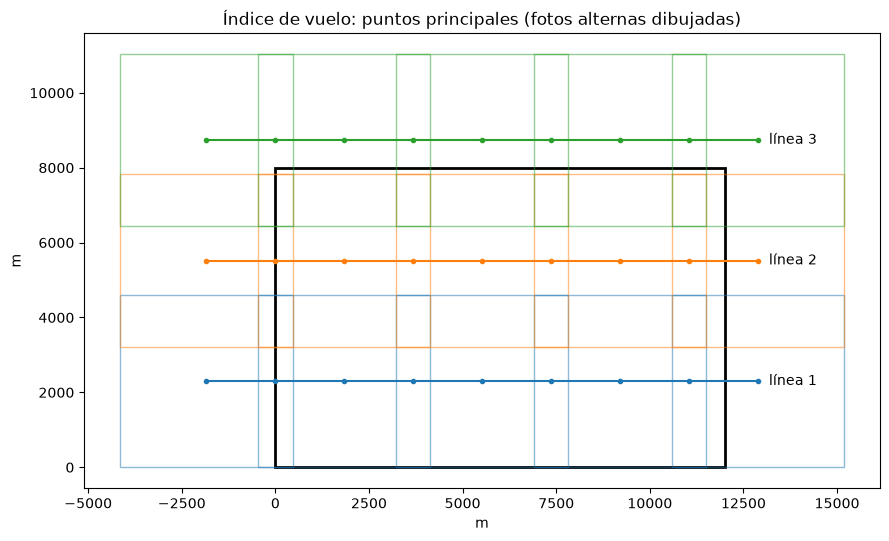

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
plt.rcParams['figure.dpi'] = 100

formato = 0.23        # lado de la foto (m)
f = 0.1524            # distancia focal (m), 6 pulgadas
escala = 20000        # denominador de la escala
traslapo_long, traslapo_lat = 0.60, 0.30
area_x, area_y = 12000, 8000   # zona a cubrir (m), las líneas de vuelo van en x

H = f * escala                          # altura de vuelo sobre el terreno
lado = formato * escala                 # cobertura de una foto en el terreno
B = lado * (1 - traslapo_long)          # base aérea
W = lado * (1 - traslapo_lat)           # separación entre líneas
n_lineas = int(np.ceil((area_y - lado) / W)) + 1
fotos_linea = int(np.ceil(area_x / B)) + 2   # se agrega una foto en cada extremo para el estéreo
print(f'Altura de vuelo: {H:.0f} m sobre el terreno')
print(f'Cobertura por foto: {lado:.0f} x {lado:.0f} m; base aérea {B:.0f} m; separación entre líneas {W:.0f} m')
print(f'{n_lineas} líneas x {fotos_linea} fotos = {n_lineas*fotos_linea} fotografías')

fig, ax = plt.subplots(figsize=(9, 6))
ax.add_patch(mpatches.Rectangle((0, 0), area_x, area_y, fill=False, lw=2, color='k'))
for i in range(n_lineas):
    yc = lado / 2 + i * W
    xs = -B + np.arange(fotos_linea) * B
    ax.plot(xs, [yc] * len(xs), 'o-', ms=3, color=f'C{i}')
    for j, xc in enumerate(xs):
        if j % 2 == 0:
            ax.add_patch(mpatches.Rectangle((xc - lado / 2, yc - lado / 2), lado, lado, fill=False, color=f'C{i}', alpha=0.5))
    ax.text(xs[-1] + 300, yc, f'línea {i+1}', va='center')
ax.set_aspect('equal'); ax.set_xlabel('m'); ax.set_ylabel('m')
ax.set_title('Índice de vuelo: puntos principales (fotos alternas dibujadas)')
plt.tight_layout(); plt.show()

## Percepción del relieve

Con un solo ojo, la visión monocular, percibimos la profundidad gracias a pistas aprendidas: la superposición, porque un objeto que tapa a otro está delante; las sombras, que revelan la forma de un objeto según la dirección de la luz; el tamaño relativo, porque los objetos conocidos se ven más pequeños cuanto más lejos están; la altura en el campo visual; la perspectiva lineal, con líneas paralelas que convergen; y el gradiente de textura, que se vuelve más fina con la distancia. La psicología de la Gestalt añade que el cerebro organiza lo que ve en formas completas y significativas; en palabras de Kurt Koffka, el todo es distinto de la suma de sus partes. Por eso un intérprete experimentado reconoce un abanico aluvial o un deslizamiento por su forma de conjunto antes de analizar sus detalles.

Las sombras tienen un efecto curioso en las fotos aéreas: si la foto se orienta de manera que las sombras caigan hacia el observador, el relieve se percibe invertido, los valles parecen crestas y viceversa. Por eso las fotos se orientan con las sombras hacia quien las mira, con la luz llegando desde arriba de la imagen.

## Visión binocular y estereoscopia

Con los dos ojos, separados unos 65 mm (la distancia interpupilar), cada ojo ve el mismo objeto desde un ángulo ligeramente distinto. El cerebro fusiona las dos imágenes y, a partir de la diferencia de ángulos, el ángulo de convergencia, estima la distancia. Este mecanismo funciona bien solo hasta unos cientos de metros, porque más allá la diferencia entre las dos visuales es imperceptible.

La fotografía aérea aprovecha el mismo principio con una base mucho mayor: dos fotos consecutivas del vuelo se tomaron desde puntos separados por la base aérea, de cientos o miles de metros. Al mirar cada foto con un ojo, el cerebro reconstruye un modelo tridimensional del terreno con el relieve exagerado, porque la relación entre la base y la altura de vuelo es mucho mayor que la relación entre la distancia interpupilar y la distancia de observación. Para lograrlo se usan estereoscopios: el de bolsillo, con dos lentes separados la distancia interpupilar, sencillo y portátil pero que obliga a superponer parcialmente las fotos; y el de espejos, que separa las fotos con un sistema de espejos y permite ver todo el traslapo, a menudo con binoculares de aumento.

Otra forma de ver en estéreo es el anaglifo. Las dos imágenes se imprimen superpuestas, una en rojo y otra en cian, y se observan con gafas de los mismos colores, de modo que cada ojo recibe una sola imagen. La celda siguiente construye un anaglifo a partir de un modelo de elevación sintético: desplaza horizontalmente cada píxel en proporción a su altura, que es lo que produce el paralaje entre dos fotos, y asigna la imagen original al canal rojo y la desplazada a los canales verde y azul. Con gafas rojo-cian el volcán y el valle se ven en relieve.

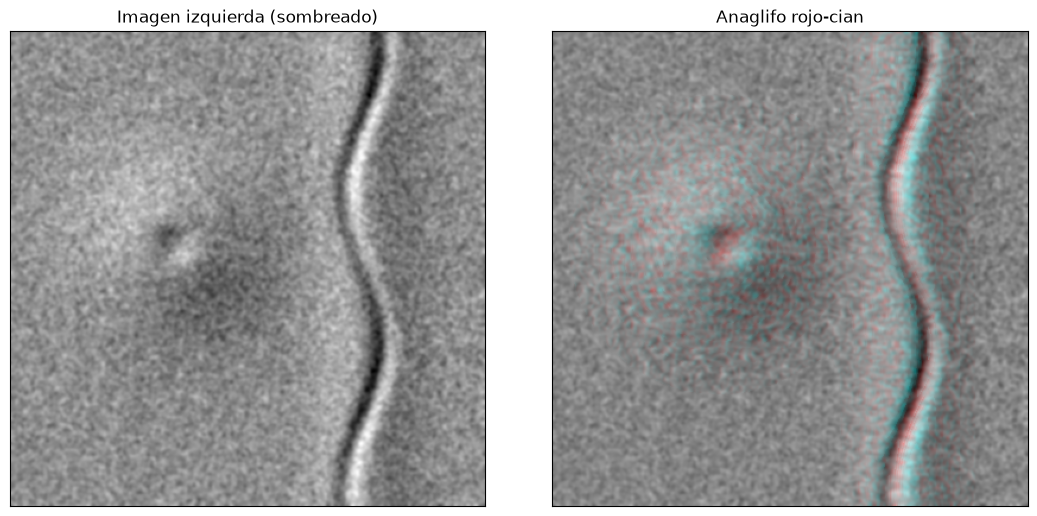

In [2]:
n = 400
rng = np.random.default_rng(2)
x, y = np.meshgrid(np.linspace(-1, 1, n), np.linspace(-1, 1, n))
r2 = (x + 0.3)**2 + (y + 0.1)**2
z = 1.0 * np.exp(-r2 / 0.12) - 0.35 * np.exp(-r2 / 0.006)                 # volcán con cráter
z += 0.5 * np.exp(-((x - 0.5)**2) / 0.03) - 0.3 * np.exp(-(x - 0.5 - 0.08 * np.sin(5 * y))**2 / 0.002)  # cuchilla cortada por un valle
from matplotlib.colors import LightSource
from scipy import ndimage
textura = ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 1.5)
textura = (textura - textura.min()) / (textura.max() - textura.min())
img = 0.65 * LightSource(azdeg=315, altdeg=40).hillshade(z, vert_exag=4) + 0.35 * textura   # sombreado más textura, como en una foto
max_desp = 12                                                       # paralaje máximo en píxeles
desp = np.round(z / z.max() * max_desp).astype(int)
derecha = np.zeros_like(img)
cols = np.arange(n)
for i in range(n):
    xi = np.clip(cols - desp[i], 0, n - 1)
    derecha[i] = img[i, xi]
anaglifo = np.dstack([img, derecha, derecha])
fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Imagen izquierda (sombreado)')
ax[1].imshow(anaglifo); ax[1].set_title('Anaglifo rojo-cian')
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Exageración vertical

En el modelo estereoscópico el relieve se ve exagerado. La exageración vertical depende principalmente de la relación entre la base aérea $B$ y la altura de vuelo $H$, y de la relación equivalente para el observador, la distancia interpupilar $b_e$ y la distancia de visión $h_e$ (unos 45 cm en un estereoscopio de espejos). Una aproximación común es

$$\mathrm{EV} \approx \frac{B / H}{b_e / h_e}.$$

Con traslapos de 60 % y cámaras de gran angular la exageración calculada así está entre 3 y 5, aunque la que percibe cada observador varía. Es una ventaja para percibir rasgos sutiles, como terrazas bajas o escarpes de falla pequeños, pero obliga a corregir las pendientes y los buzamientos que se estiman visualmente, como se verá en el capítulo {doc}`09_Fotogeologia`.

In [3]:
b_e, h_e = 0.065, 0.45
for f_mm, nombre in [(88, 'súper gran angular'), (152, 'gran angular'), (305, 'angular normal')]:
    escala_v = 20000
    H_v = f_mm / 1000 * escala_v
    B_v = 0.23 * escala_v * 0.4
    print(f'{nombre:20s} f = {f_mm} mm: H = {H_v:5.0f} m, B = {B_v:5.0f} m, B/H = {B_v/H_v:4.2f}, EV = {(B_v/H_v)/(b_e/h_e):4.1f}')

súper gran angular   f = 88 mm: H =  1760 m, B =  1840 m, B/H = 1.05, EV =  7.2
gran angular         f = 152 mm: H =  3040 m, B =  1840 m, B/H = 0.61, EV =  4.2
angular normal       f = 305 mm: H =  6100 m, B =  1840 m, B/H = 0.30, EV =  2.1


## Para profundizar

Los capítulos 1 a 3 de {cite}`ray1960` describen la fotografía aérea y la estereoscopia orientadas a la geología. El manual de {cite:t}`pacheco2006` trae ejercicios de laboratorio con estereoscopio, y el capítulo 3 de {cite}`lillesand2015` trata la fotografía aérea desde el punto de vista de la teledetección. El taller de anaglifos del curso explica cómo construir y observar anaglifos con fotos reales.